In [1]:
from pathlib import Path
import ast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

pd.set_option("display.max_rows", 50)
SEED = 42

In [2]:
from pathlib import Path

# Colab
RESULTS_PATH = Path("/content/traditional_notebook_outputs")

# Local (uncomment instead)
# RESULTS_PATH = Path("diplomacy-deception-detection/traditional_notebook_outputs")

for name in ["metrics.csv", "predictions.csv"]:
    print(RESULTS_PATH / name, ":", (RESULTS_PATH / name).exists())

/content/traditional_notebook_outputs/metrics.csv : True
/content/traditional_notebook_outputs/predictions.csv : True


In [3]:
metrics_file = RESULTS_PATH / "metrics.csv"
predictions_file = RESULTS_PATH / "predictions.csv"

if not metrics_file.is_file() or not predictions_file.is_file():
    raise FileNotFoundError("Place metrics.csv and predictions.csv inside RESULTS_PATH")

metrics = pd.read_csv(metrics_file)
predictions = pd.read_csv(predictions_file)

# Remove fully empty CSV rows only.
key_columns = ["task", "model", "split", "message_id", "target", "prediction"]
missing = set(key_columns) - set(predictions.columns)
if missing:
    raise ValueError(f"Missing prediction columns: {sorted(missing)}")

blank = predictions[key_columns].isna().all(axis=1)
print("Fully empty prediction rows:", int(blank.sum()))
predictions = predictions.loc[~blank].copy()

# Reject partial records instead of silently deleting predictions.
invalid = predictions[predictions[key_columns].isna().any(axis=1)]
if not invalid.empty:
    display(invalid.head(10))
    raise ValueError(f"{len(invalid)} prediction rows have missing fields. Fix the CSV export.")

for column in ["target", "prediction"]:
    predictions[column] = pd.to_numeric(predictions[column], errors="raise")
    if not predictions[column].isin([0, 1]).all():
        raise ValueError(f"Invalid values in {column}: {predictions[column].value_counts(dropna=False).to_dict()}")
    predictions[column] = predictions[column].astype(int)

print("Metrics shape:", metrics.shape)
print("Predictions shape:", predictions.shape)
display(metrics.head(3))
display(predictions.head(3))

Fully empty prediction rows: 0
Metrics shape: (40, 14)
Predictions shape: (79150, 7)


,task,model,split,representation,classifier,parameters,n_samples,accuracy,precision,recall,lie_f1,macro_f1,confusion_matrix,pr_auc
0,actual_lie,01_random,validation,none,random,"{'seed': 42, 'train_lie_rate': 0.0450045689917...",1416,0.918079,0.045455,0.053571,0.049180,0.503188,"[[1297, 63], [53, 3]]",NaN
1,actual_lie,01_random,test,none,random,"{'seed': 42, 'train_lie_rate': 0.0450045689917...",2741,0.871215,0.093525,0.054167,0.068602,0.499713,"[[2375, 126], [227, 13]]",NaN
2,actual_lie,02_majority,validation,none,majority,{'majority_class': 0},1416,0.960452,0.000000,0.000000,0.000000,0.489914,"[[1360, 0], [56, 0]]",0.039548


,task,model,split,message_id,target,prediction,score
0,actual_lie,01_random,validation,11:0:0,0,0,0.045005
1,actual_lie,01_random,validation,11:0:1,0,0,0.045005
2,actual_lie,01_random,validation,11:0:2,0,0,0.045005


## Validate task labels, models, and row counts

In [4]:
MODEL_ORDER = [
    "01_random", "02_majority", "03_harbingers", "04_logistic_regression",
    "05_harbingers_lr", "06_harbingers_power", "07_harbingers_lr_power",
    "08_bow_lr", "09_bow_power", "10_bow_lr_power"
]
TASKS = ["actual_lie", "suspected_lie"]
SPLITS = ["validation", "test"]

required_metrics = {"task", "model", "split", "accuracy", "macro_f1", "lie_f1", "precision", "recall"}
required_predictions = {"task", "model", "split", "message_id", "target", "prediction"}
assert required_metrics.issubset(metrics.columns), required_metrics - set(metrics.columns)
assert required_predictions.issubset(predictions.columns), required_predictions - set(predictions.columns)
assert metrics.duplicated(["task", "model", "split"]).sum() == 0
assert predictions["target"].isin([0, 1]).all(), "Invalid target labels"
assert predictions["prediction"].isin([0, 1]).all(), "Invalid predicted labels"
assert predictions.duplicated(["task", "model", "split", "message_id"]).sum() == 0

expected = {(t, m, s) for t in TASKS for m in MODEL_ORDER for s in SPLITS}
observed = set(map(tuple, metrics[["task", "model", "split"]].itertuples(index=False, name=None)))
print("Missing model/task/split combinations:", len(expected - observed))
print("Extra combinations:", len(observed - expected))
assert observed == expected, "Expected results for all 10 models, both tasks and both splits"

counts = predictions.groupby(["task", "model", "split"]).size()
print("Prediction rows for first few experiments:")
display(counts.head(8).to_frame("rows"))

for (task, model, split), group in predictions.groupby(["task", "model", "split"]):
    row = metrics[(metrics["task"] == task) & (metrics["model"] == model) & (metrics["split"] == split)].iloc[0]
    if "n_samples" in metrics:
        assert len(group) == int(row["n_samples"])
print("All basic result checks passed.")

Missing model/task/split combinations: 0
Extra combinations: 0
Prediction rows for first few experiments:


rows
task       model                  split           
actual_lie 01_random              test        2741
                                  validation  1416
           02_majority            test        2741
                                  validation  1416
           03_harbingers          test        2741
                                  validation  1416
           04_logistic_regression test        2741
                                  validation  1416

All basic result checks passed.


## Read model specifications

In [5]:
spec = metrics[metrics["split"] == "validation"][[
    "model", "representation", "classifier"
]].drop_duplicates().sort_values("model")
display(spec)

print("These are ten experiment IDs, not necessarily ten distinct learned classifiers.")

,model,representation,classifier
0,01_random,none,random
2,02_majority,none,majority
4,03_harbingers,harbingers,logistic_regression
6,04_logistic_regression,numerical,logistic_regression
8,05_harbingers_lr,harbingers,logistic_regression
10,06_harbingers_power,harbingers+power,logistic_regression
12,07_harbingers_lr_power,harbingers+power,logistic_regression
14,08_bow_lr,bow,logistic_regression
16,09_bow_power,bow+power,logistic_regression
18,10_bow_lr_power,bow+power,logistic_regression


These are ten experiment IDs, not necessarily ten distinct learned classifiers.


## Compare validation Macro F1

task,Actual lie (%),Suspected lie (%)
model,,
01_random,50.32,47.82
02_majority,48.99,49.07
03_harbingers,48.99,49.07
04_logistic_regression,49.32,49.07
05_harbingers_lr,48.99,49.07
06_harbingers_power,48.99,49.07
07_harbingers_lr_power,48.99,49.07
08_bow_lr,50.57,51.30
09_bow_power,51.46,51.41


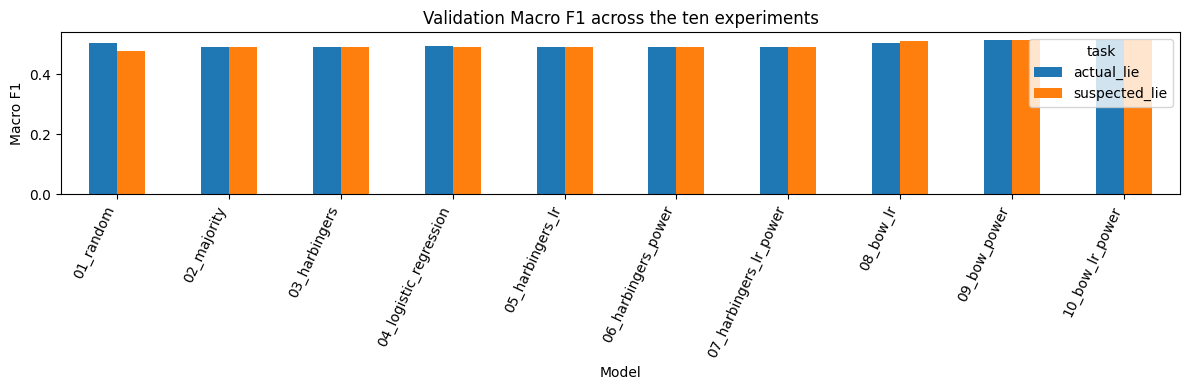

In [6]:
validation = metrics[metrics["split"] == "validation"].copy()
val_table = validation.pivot(index="model", columns="task", values="macro_f1").reindex(MODEL_ORDER)
display((100 * val_table).round(2).rename(columns={
    "actual_lie": "Actual lie (%)", "suspected_lie": "Suspected lie (%)"
}))

ax = val_table.plot.bar(figsize=(12, 4))
ax.set_title("Validation Macro F1 across the ten experiments")
ax.set_ylabel("Macro F1")
ax.set_xlabel("Model")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

## Compare validation lie-class F1

task,actual_lie,suspected_lie
model,,
01_random,4.92,0.00
02_majority,0.00,0.00
03_harbingers,0.00,0.00
04_logistic_regression,13.49,0.00
05_harbingers_lr,0.00,0.00
06_harbingers_power,0.00,0.00
07_harbingers_lr_power,0.00,0.00
08_bow_lr,3.28,5.41
09_bow_power,12.03,5.56


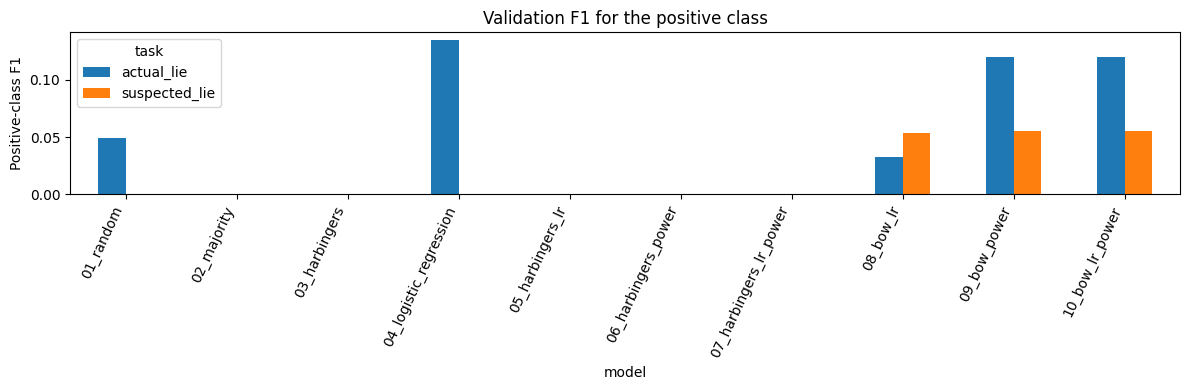

In [7]:
val_lie = validation.pivot(index="model", columns="task", values="lie_f1").reindex(MODEL_ORDER)
display((100 * val_lie).round(2))

ax = val_lie.plot.bar(figsize=(12, 4))
ax.set_title("Validation F1 for the positive class")
ax.set_ylabel("Positive-class F1")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

## Select models on validation only

In [8]:
selected = {}
for task in TASKS:
    ranked = validation[validation["task"] == task].sort_values(
        ["macro_f1", "lie_f1", "model"], ascending=[False, False, True]
    )
    best = ranked.iloc[0]
    selected[task] = best["model"]
    print(task, "->", best["model"],
          "| validation Macro F1:", round(float(best["macro_f1"]), 4),
          "| validation positive F1:", round(float(best["lie_f1"]), 4))

actual_lie -> 09_bow_power | validation Macro F1: 0.5146 | validation positive F1: 0.1203
suspected_lie -> 09_bow_power | validation Macro F1: 0.5141 | validation positive F1: 0.0556


## Report test metrics

In [9]:
test = metrics[metrics["split"] == "test"].copy()
for task in TASKS:
    print("\nTask:", task)
    subset = test[test["task"] == task].set_index("model").reindex(MODEL_ORDER)
    columns = ["accuracy", "precision", "recall", "lie_f1", "macro_f1"]
    if "pr_auc" in subset.columns:
        columns.append("pr_auc")
    display((100 * subset[columns]).round(2))

    chosen = subset.loc[selected[task]]
    print("Validation-selected model:", selected[task])
    print("Test Macro F1:", round(float(chosen["macro_f1"]), 4))


Task: actual_lie


,accuracy,precision,recall,lie_f1,macro_f1,pr_auc
model,,,,,,
01_random,87.12,9.35,5.42,6.86,49.97,NaN
02_majority,91.24,0.00,0.00,0.00,47.71,8.76
03_harbingers,91.24,0.00,0.00,0.00,47.71,14.10
04_logistic_regression,66.98,13.82,52.92,21.92,50.49,14.34
05_harbingers_lr,91.24,0.00,0.00,0.00,47.71,14.10
06_harbingers_power,91.24,0.00,0.00,0.00,47.71,14.67
07_harbingers_lr_power,91.24,0.00,0.00,0.00,47.71,14.67
08_bow_lr,90.81,30.00,3.75,6.67,50.92,14.28
09_bow_power,77.13,16.23,38.75,22.88,54.72,15.82


Validation-selected model: 09_bow_power
Test Macro F1: 0.5472

Task: suspected_lie


,accuracy,precision,recall,lie_f1,macro_f1,pr_auc
model,,,,,,
01_random,88.93,7.09,5.45,6.16,50.14,NaN
02_majority,93.33,0.00,0.00,0.00,48.28,6.67
03_harbingers,93.33,0.00,0.00,0.00,48.28,6.65
04_logistic_regression,93.33,0.00,0.00,0.00,48.28,9.77
05_harbingers_lr,93.33,0.00,0.00,0.00,48.28,6.65
06_harbingers_power,93.33,0.00,0.00,0.00,48.28,7.21
07_harbingers_lr_power,93.33,0.00,0.00,0.00,48.28,7.21
08_bow_lr,91.11,10.14,4.24,5.98,50.66,8.02
09_bow_power,91.23,11.76,4.85,6.87,51.13,8.15


Validation-selected model: 09_bow_power
Test Macro F1: 0.5113


## Plot test Macro F1 and positive-class F1

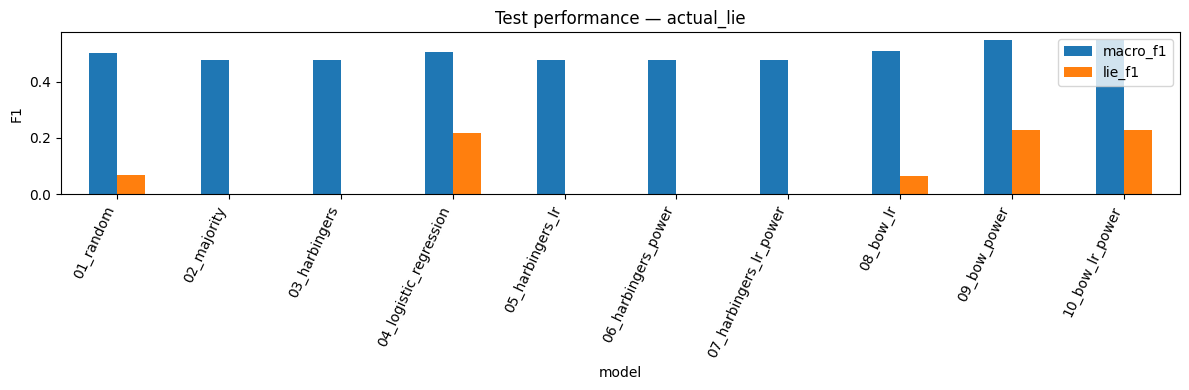

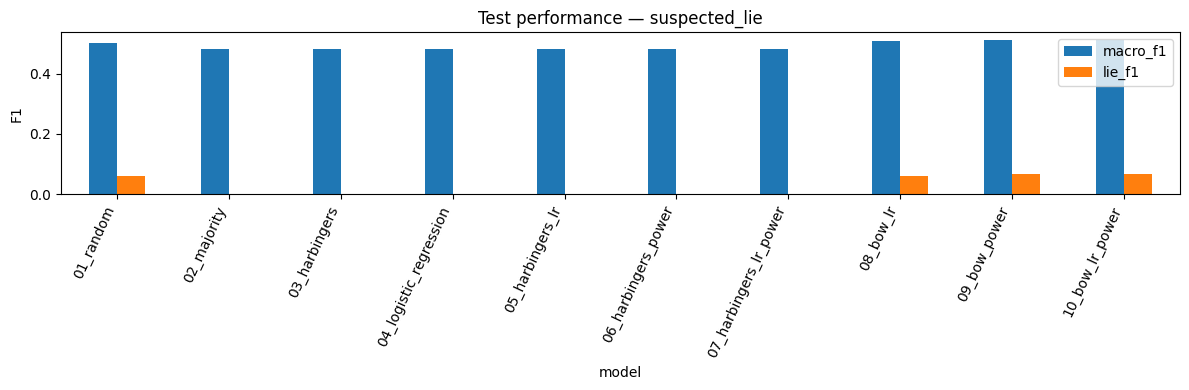

In [10]:
for task in TASKS:
    subset = test[test["task"] == task].set_index("model").reindex(MODEL_ORDER)
    ax = subset[["macro_f1", "lie_f1"]].plot.bar(figsize=(12, 4))
    ax.set_title(f"Test performance — {task}")
    ax.set_ylabel("F1")
    plt.xticks(rotation=65, ha="right")
    plt.tight_layout()
    plt.show()

## Confusion matrices for validation-selected models

actual_lie | 09_bow_power | confusion matrix:
[[2021  480]
 [ 147   93]]


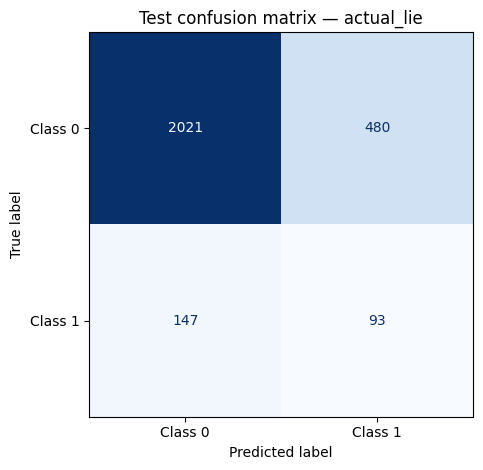

suspected_lie | 09_bow_power | confusion matrix:
[[2250   60]
 [ 157    8]]


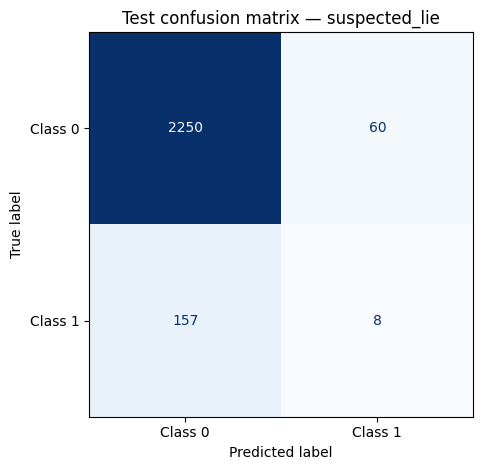

In [11]:
for task in TASKS:
    model = selected[task]
    subset = predictions[
        (predictions["task"] == task) &
        (predictions["model"] == model) &
        (predictions["split"] == "test")
    ]
    cm = confusion_matrix(subset["target"], subset["prediction"], labels=[0, 1])
    print(task, "|", model, "| confusion matrix:")
    print(cm)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Class 0", "Class 1"])
    disp.plot(values_format="d", cmap="Blues", colorbar=False)
    plt.title(f"Test confusion matrix — {task}")
    plt.tight_layout()
    plt.show()

## Check precision, recall, and prediction behavior

In [12]:
behavior_rows = []
for task in TASKS:
    model = selected[task]
    for split in SPLITS:
        subset = predictions[
            (predictions["task"] == task) &
            (predictions["model"] == model) &
            (predictions["split"] == split)
        ]
        behavior_rows.append({
            "task": task, "model": model, "split": split,
            "n_messages": len(subset),
            "actual_positive_percent": 100 * subset["target"].mean(),
            "predicted_positive_percent": 100 * subset["prediction"].mean()
        })
display(pd.DataFrame(behavior_rows).round(2))

,task,model,split,n_messages,actual_positive_percent,predicted_positive_percent
0,actual_lie,09_bow_power,validation,1416,3.95,14.83
1,actual_lie,09_bow_power,test,2741,8.76,20.90
2,suspected_lie,09_bow_power,validation,1283,3.66,1.95
3,suspected_lie,09_bow_power,test,2475,6.67,2.75


## Study the contribution of power features

In [13]:
POWER_PAIRS = [
    ("03_harbingers", "06_harbingers_power", "Harbingers"),
    ("05_harbingers_lr", "07_harbingers_lr_power", "Harbingers + LR"),
    ("08_bow_lr", "09_bow_power", "BoW"),
    ("08_bow_lr", "10_bow_lr_power", "BoW + LR")
]

power_rows = []
for task in TASKS:
    for split in SPLITS:
        subset = metrics[(metrics["task"] == task) & (metrics["split"] == split)].set_index("model")
        for without, with_power, label in POWER_PAIRS:
            power_rows.append({
                "task": task, "split": split, "pair": label,
                "without_power": without,
                "with_power": with_power,
                "macro_f1_change": subset.loc[with_power, "macro_f1"] - subset.loc[without, "macro_f1"],
                "lie_f1_change": subset.loc[with_power, "lie_f1"] - subset.loc[without, "lie_f1"]
            })
power_comparison = pd.DataFrame(power_rows)
print("Validation changes (percentage points):")
display((power_comparison[power_comparison["split"] == "validation"].assign(
    macro_f1_change=lambda x: (100 * x["macro_f1_change"]).round(2),
    lie_f1_change=lambda x: (100 * x["lie_f1_change"]).round(2)
)))

Validation changes (percentage points):


,task,split,pair,without_power,with_power,macro_f1_change,lie_f1_change
0,actual_lie,validation,Harbingers,03_harbingers,06_harbingers_power,0.00,0.00
1,actual_lie,validation,Harbingers + LR,05_harbingers_lr,07_harbingers_lr_power,0.00,0.00
2,actual_lie,validation,BoW,08_bow_lr,09_bow_power,0.88,8.75
3,actual_lie,validation,BoW + LR,08_bow_lr,10_bow_lr_power,0.88,8.75
8,suspected_lie,validation,Harbingers,03_harbingers,06_harbingers_power,0.00,0.00
9,suspected_lie,validation,Harbingers + LR,05_harbingers_lr,07_harbingers_lr_power,0.00,0.00
10,suspected_lie,validation,BoW,08_bow_lr,09_bow_power,0.12,0.15
11,suspected_lie,validation,BoW + LR,08_bow_lr,10_bow_lr_power,0.12,0.15


## Check overlapping experiment IDs

In [14]:
DUPLICATE_PAIRS = [
    ("03_harbingers", "05_harbingers_lr"),
    ("06_harbingers_power", "07_harbingers_lr_power"),
    ("09_bow_power", "10_bow_lr_power")
]

pair_results = []
for task in TASKS:
    for split in SPLITS:
        for model_a, model_b in DUPLICATE_PAIRS:
            a = predictions[(predictions["task"] == task) & (predictions["split"] == split) & (predictions["model"] == model_a)][["message_id", "prediction"]]
            b = predictions[(predictions["task"] == task) & (predictions["split"] == split) & (predictions["model"] == model_b)][["message_id", "prediction"]]
            merged = a.merge(b, on="message_id", how="outer", suffixes=("_a", "_b"), indicator=True)
            identical = (len(merged) == len(a) == len(b) and
                         (merged["_merge"] == "both").all() and
                         (merged["prediction_a"] == merged["prediction_b"]).all())
            pair_results.append({"task": task, "split": split,
                                 "model_a": model_a, "model_b": model_b,
                                 "same_predictions": identical})
display(pd.DataFrame(pair_results))

,task,split,model_a,model_b,same_predictions
0,actual_lie,validation,03_harbingers,05_harbingers_lr,True
1,actual_lie,validation,06_harbingers_power,07_harbingers_lr_power,True
2,actual_lie,validation,09_bow_power,10_bow_lr_power,True
3,actual_lie,test,03_harbingers,05_harbingers_lr,True
4,actual_lie,test,06_harbingers_power,07_harbingers_lr_power,True
5,actual_lie,test,09_bow_power,10_bow_lr_power,True
6,suspected_lie,validation,03_harbingers,05_harbingers_lr,True
7,suspected_lie,validation,06_harbingers_power,07_harbingers_lr_power,True
8,suspected_lie,validation,09_bow_power,10_bow_lr_power,True
9,suspected_lie,test,03_harbingers,05_harbingers_lr,True


## Compare actual-lie and suspected-lie tasks

In [15]:
task_table = metrics.pivot_table(
    index=["model", "split"], columns="task", values=["macro_f1", "lie_f1"]
).reindex(pd.MultiIndex.from_product([MODEL_ORDER, SPLITS], names=["model", "split"]))
display((100 * task_table).round(2))

counts = predictions.groupby(["task", "split", "model"]).agg(
    messages=("target", "size"),
    positive_rate=("target", "mean")
).reset_index()
display(counts[counts["model"] == "02_majority"].round(3))

lie_f1                 macro_f1  \
task                              actual_lie suspected_lie actual_lie   
model                  split                                            
01_random              validation       4.92          0.00      50.32   
                       test             6.86          6.16      49.97   
02_majority            validation       0.00          0.00      48.99   
                       test             0.00          0.00      47.71   
03_harbingers          validation       0.00          0.00      48.99   
                       test             0.00          0.00      47.71   
04_logistic_regression validation      13.49          0.00      49.32   
                       test            21.92          0.00      50.49   
05_harbingers_lr       validation       0.00          0.00      48.99   
                       test             0.00          0.00      47.71   
06_harbingers_power    validation       0.00          0.00      48.99   
                       test             0.00          0.00      47.71   
07_harbingers_lr_power validation       0.00          0.00      48.99   
                       test             0.00          0.00      47.71   
08_bow_lr              validation       3.28          5.41      50.57   
                       test             6.67          5.98      50.92   
09_bow_power           validation      12.03          5.56      51.46   
                       test            22.88          6.87      54.72   
10_bow_lr_power        validation      12.03          5.56      51.46   
                       test            22.88          6.87      54.72   

                                                 
task                              suspected_lie  
model                  split                     
01_random              validation         47.82  
                       test               50.14  
02_majority            validation         49.07  
                       test               48.28  
03_harbingers          validation         49.07  
                       test               48.28  
04_logistic_regression validation         49.07  
                       test               48.28  
05_harbingers_lr       validation         49.07  
                       test               48.28  
06_harbingers_power    validation         49.07  
                       test               48.28  
07_harbingers_lr_power validation         49.07  
                       test               48.28  
08_bow_lr              validation         51.30  
                       test               50.66  
09_bow_power           validation         51.41  
                       test               51.13  
10_bow_lr_power        validation         51.41  
                       test               51.13

,task,split,model,messages,positive_rate
1,actual_lie,test,02_majority,2741,0.088
11,actual_lie,validation,02_majority,1416,0.040
21,suspected_lie,test,02_majority,2475,0.067
31,suspected_lie,validation,02_majority,1283,0.037


## Compare with the published paper (actual lie)

In [16]:
paper = pd.DataFrame([
    {"paper_model": "Random", "our_model": "01_random", "paper_macro_f1": 39.8, "paper_lie_f1": 14.9},
    {"paper_model": "Majority", "our_model": "02_majority", "paper_macro_f1": 47.8, "paper_lie_f1": np.nan},
    {"paper_model": "Harbingers", "our_model": "03_harbingers", "paper_macro_f1": 52.8, "paper_lie_f1": 24.6},
    {"paper_model": "Harbingers + Power", "our_model": "06_harbingers_power", "paper_macro_f1": 52.9, "paper_lie_f1": 23.7},
    {"paper_model": "BoW", "our_model": "08_bow_lr", "paper_macro_f1": 54.3, "paper_lie_f1": 19.1},
    {"paper_model": "BoW + Power", "our_model": "09_bow_power", "paper_macro_f1": 54.9, "paper_lie_f1": 20.2},
])

actual_test = test[test["task"] == "actual_lie"][["model", "macro_f1", "lie_f1"]].copy()
actual_test[["macro_f1", "lie_f1"]] *= 100
actual_test = actual_test.rename(columns={
    "model": "our_model", "macro_f1": "our_macro_f1", "lie_f1": "our_lie_f1"
})
paper_comparison = paper.merge(actual_test, on="our_model", how="left")
paper_comparison["macro_f1_difference"] = (
    paper_comparison["our_macro_f1"] - paper_comparison["paper_macro_f1"]
)
paper_comparison["lie_f1_difference"] = (
    paper_comparison["our_lie_f1"] - paper_comparison["paper_lie_f1"]
)
display(paper_comparison.round(2))

,paper_model,our_model,paper_macro_f1,paper_lie_f1,our_macro_f1,our_lie_f1,macro_f1_difference,lie_f1_difference
0,Random,01_random,39.8,14.9,49.97,6.86,10.17,-8.04
1,Majority,02_majority,47.8,NaN,47.71,0.00,-0.09,NaN
2,Harbingers,03_harbingers,52.8,24.6,47.71,0.00,-5.09,-24.60
3,Harbingers + Power,06_harbingers_power,52.9,23.7,47.71,0.00,-5.19,-23.70
4,BoW,08_bow_lr,54.3,19.1,50.92,6.67,-3.38,-12.43
5,BoW + Power,09_bow_power,54.9,20.2,54.72,22.88,-0.18,2.68


## Visualize published versus observed Macro F1

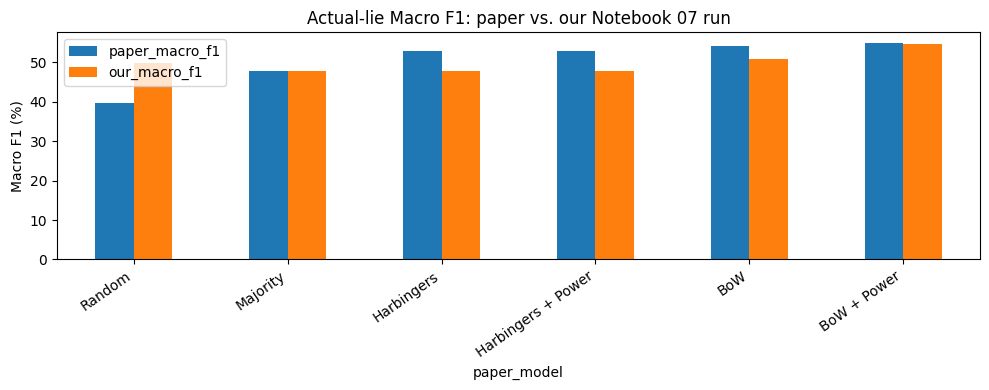

In [17]:
comparison_plot = paper_comparison.set_index("paper_model")[["paper_macro_f1", "our_macro_f1"]]
comparison_plot.plot.bar(figsize=(10, 4))
plt.title("Actual-lie Macro F1: paper vs. our Notebook 07 run")
plt.ylabel("Macro F1 (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## Inspect example false positives and false negatives

In [18]:
TASK = "actual_lie"
MODEL = selected[TASK]

errors = predictions[
    (predictions["task"] == TASK) &
    (predictions["model"] == MODEL) &
    (predictions["split"] == "test") &
    (predictions["target"] != predictions["prediction"])
].copy()
errors["error_type"] = np.where(
    errors["target"] == 1, "False negative", "False positive"
)

print("Task:", TASK, "| Model:", MODEL, "| Errors:", len(errors))
display(errors[["message_id", "target", "prediction", "score", "error_type"]].head(15))

Task: actual_lie | Model: 09_bow_power | Errors: 627


,message_id,target,prediction,score,error_type
34679,12:1:2,1,0,0.098270,False negative
34693,12:3:0,0,1,0.663494,False positive
34695,12:3:2,0,1,0.563196,False positive
34705,12:4:9,0,1,0.581207,False positive
34706,12:4:10,0,1,0.676421,False positive
34714,12:4:18,0,1,0.717782,False positive
34719,12:4:23,0,1,0.792650,False positive
34731,12:4:35,1,0,0.211204,False negative
34749,12:5:10,0,1,0.563343,False positive
34751,12:5:12,0,1,0.573459,False positive
